# Lesson 10b: Multi-Atomic Cluster Expansion (MACE)

**What you will learn**

- How MACE combines the **density trick** of the atomic cluster expansion (ACE,
  Lesson 10a) with **equivariant message passing** (Lessons 06a and 08a): every
  MACE message is an ACE itself.
- The anatomy of the MACE layer, equation by equation: the **$A$-basis** built
  from radial functions, spherical harmonics and learned neighbor features, the
  higher-order $B$-features from generalized Clebsch–Gordan contractions,
  and the linear message, update and readout.
- How body order is counted: a layer with correlation order $\nu = 3$ gives
  4-body features, and two such layers reach 13-body features.
- The **design-space** view, which places SchNet, DimeNet, NequIP, BOTNet,
  linear ACE and MACE in one framework.
- Why MACE is **fast**.

**Prerequisites:**

- [Lessons 03a](03a_tensor_products_theory.ipynb) and
  [03b](03b_tensor_products_e3nn.ipynb): Tensor products and Clebsch–Gordan
  coefficients,
- [Lesson 06a](06a_equivariant_convolution.ipynb): Equivariant convolution,
- [Lesson 08a](08a_nequip_theory.ipynb): The NequIP architecture,
- [Lesson 10a](10a_ace_theory.ipynb): ACE, the density trick and the
  $B$-basis.

In [1]:
import sys; sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import torch
from e3nn import o3

torch.manual_seed(0)
# This is a theory notebook and the code base is tiny. So, we use float64
# everywhere and the numerical checks stay within machine precision.
torch.set_default_dtype(torch.float64)
device = "cpu"
print(f"torch {torch.__version__}")

torch 2.7.1+cu126


## From ACE and NequIP to MACE

Lesson 10a ended with citing two methods for reaching a high body order in the
design space:

- **ACE**, which reaches any body order in a single, strictly local layer. Its
  basis is fixed, its readout is linear, and its element channels grow as
  $S^\nu$ for $S$ chemical elements.
- **Equivariant message passing** framework, which allows models to learn their
  chemical features from data and provide accurate predictions. For example,
  NequIP's message is 2-body, but its body order can grow only by stacking
  message passing layers ($T \approx 5$). Every layer also adds one cutoff to
  the model's receptive field, making its computational cost more expensive.

[MACE
](https://proceedings.neurips.cc/paper_files/paper/2022/file/4a36c3c51af11ed9f34615b81edb5bbc-Paper-Conference.pdf)
combines ACE and equivariant message passing by turning each message into a
cluster expansion and thus, follows the standard message-passing framework with
the state of node $i$ in layer $t$, $\sigma_i^{(t)}$, defined as

$$\sigma_i^{(t)} = \big(\vec r_i,\, z_i,\, h_i^{(t)}\big).$$

Here, $\vec r_i \in \mathbb{R}^3$, is the position of atom $i$, $z_i$,
represents its chemical element and $h_i^{(t)}$ stands for its learnable
features. A forward pass in MACE involves three steps: Message construction,
update, and readout. The message construction pools all messages from the
neighboring atoms, $\mathcal N(i)$, of a central atom $i$, within a cutoff
radius as,

$$m_i^{(t)} = \bigoplus_{j \in \mathcal N(i)} M_t\big(\sigma_i^{(t)}, \sigma_j^{(t)}\big),$$

where $M_t$ is a learnable message function and $\bigoplus$ is a
permutation-invariant pooling operation, such as summation. The **update** step
is defined as,

$$h_i^{(t+1)} = U_t\big(\sigma_i^{(t)}, m_i^{(t)}\big).$$

All features are $O(3)$-equivariant. Each feature entry, $h^{(t)}_{i,kLM}$,
often carries a channel index $k$, an angular momentum $L$ and a component $M$,
and transforms under $Q \in O(3)$ with the Wigner matrix $D^{(L)}(Q)$. Entries
with $L = 0$ are invariant scalars and entries with $L > 0$ are equivariant.

After $T$ message-passing layers, the readout, $R_t$, maps the node states,
$\sigma_i^{(t)}$, to the site energies, $E_i$, as

$$E_i = \sum_{t=1}^{T} R_t\big(\sigma_i^{(t)}\big).$$

## Body-ordered messages in MACE

MACE's key ingredient is its message function, $M_t$. Instead of a 2-body
message, which depends on one neighbor at a time, MACE's message is a
**hierarchical body-order expansion**:

$$m_i^{(t)} = \sum_j u_1\big(\sigma_i^{(t)}; \sigma_j^{(t)}\big) + \sum_{j_1, j_2} u_2\big(\sigma_i^{(t)}; \sigma_{j_1}^{(t)}, \sigma_{j_2}^{(t)}\big) + \cdots + \sum_{j_1, \dots, j_\nu} u_\nu\big(\sigma_i^{(t)}; \sigma_{j_1}^{(t)}, \dots, \sigma_{j_\nu}^{(t)}\big),$$

which is comprised of trainable functions, $u_1, \dots, u_\nu$, and sums over
the neighbors of $i$. The hyperparameter $\nu$ is the maximum correlation
order of the message which corresponds to its body order minus 1 with respect
to each node state. Two notes about the MACE messages should be highlighted:

1. The sums over $j_1, \dots, j_\nu$ are **unrestricted**: they include
   self-interaction terms, corresponding to cases such as $j_1 = j_2$. This is a
   choice behind the density trick (Lesson 10a) which allows us to circumvent
   the exponential cost of expensive terms with the correlation order $\nu$.
   DimeNet, by contrast, sums explicitly over triplets $j_1 < j_2$.
2. The atomic states at each layer, $\sigma_j^{(t)}$, carry many-body
   information from earlier layers. As such, the body order with respect to the positions
   can be much higher than $\nu + 1$. We will return to this point in
   the proceeding sections.

Each MACE layer involves three main stages: calculation of the $A$-basis,
creating the $B$-basis and computing a linear message. These phases mirror the
three steps of ACE framework in Lesson 10a: the atomic base, the symmetrized
products and the linear mapping. In the following sections, we will go through
each of these steps in detail.

## MACE layer

### $A$-basis functions as pooled 2-body features

Each MACE layer embeds the edges with a learnable radial basis $R^{(t)}$, the
spherical harmonics $Y^{(l)}_m$ and a learnable linear embedding $W^{(t)}$ of
the sender node's features. Then, it pools the resulting features over
contributions from the neighboring atoms, $\mathcal N(i)$,

$$A^{(t)}_{i,kl_3m_3} = \sum_{l_1m_1,\,l_2m_2} C^{(l_3,m_3)}_{(l_1,m_1)(l_2,m_2)} \sum_{j \in \mathcal N(i)} R^{(t)}_{kl_1l_2l_3}(r_{ji})\, Y^{(l_1)}_{m_1}(\hat r_{ji}) \sum_{\tilde k} W^{(t)}_{k\tilde kl_2}\, h^{(t)}_{j,\tilde kl_2m_2}.$$

Here $C^{(l_3,m_3)}_{(l_1,m_1)(l_2,m_2)}$ are the Clebsch-Gordan (CG)
coefficients (Lesson 03a), $r_{ji}$ is the interatomic distance and $\hat
r_{ji}$ the unit vector along the bond. The aforementioned equation is the
**e3nn point convolution** of Lesson 06a: a weighted tensor product of the edge
spherical harmonics with the neighbor features, summed over the neighbors. The
radial weights $R^{(t)}_{kl_1l_2l_3}$, coming from Bessel functions, times a
smooth polynomial cutoff, fed through an MLP (Lesson 05b). The experiments in
the [MACE manuscript
](https://proceedings.neurips.cc/paper_files/paper/2022/file/4a36c3c51af11ed9f34615b81edb5bbc-Paper-Conference.pdf)
use 8 Bessel functions, a polynomial envelope with $p = 5$ and an MLP of size
$[64, 64, 64, 1024]$ with SiLU activations.

In the **first MACE layer**, the node features are just the (invariant) chemical
elements, $z_j$ which simplifies the $A$-basis to

$$A^{(1)}_{i,kl_1m_1} = \sum_{j \in \mathcal N(i)} R^{(1)}_{kl_1}(r_{ji})\, Y^{(l_1)}_{m_1}(\hat r_{ji})\, W^{(1)}_{kz_j}.$$

This is equivalent to the **ACE atomic basis** of Lesson 10a, $A_{i,nlm} =
\sum_j R_{nl}(r_{ij})\, Y^{(l)}_m(\hat r_{ij})$, with two changes: the radial
index $n$ becomes a learnable channel $k$, and a learned weight per element
replaces the discrete species index. No tensor product with neighboring features
is needed here, which makes the first layer computationally cheap. 

### $B$-basis functions as higher-order tensor product features

Another key operation in MACE is to multiply $\nu$ copies of the $A$-features
and couple their products back to the irreps space via **generalized CG
coefficients**:

$$B^{(t)}_{i,\eta_\nu kLM} = \sum_{\boldsymbol{lm}} \mathcal C^{LM}_{\eta_\nu,\boldsymbol{lm}} \prod_{\xi=1}^{\nu} \sum_{\tilde k} w^{(t)}_{k\tilde kl_\xi}\, A^{(t)}_{i,\tilde kl_\xi m_\xi}, \qquad \boldsymbol{lm} = (l_1m_1, \dots, l_\nu m_\nu).$$

The index $\eta_\nu$ enumerates the ways of coupling $l_1, \dots, l_\nu$ to the
output symmetry $L$, and the weights, $w^{(t)}_{k\tilde kl_\xi}$, mix the
channels. The generalized CG coefficients, $\mathcal
C^{LM}_{\eta_\nu,\boldsymbol{lm}}$, are iterated pairwise CG contractions.
Lesson 10a used a special case of generalized CGs, the Wigner $3j$ symbol, that
couples three atomic bases to $L = 0$. The CG coefficients are very sparse and
are often precomputed. Therefore, the $A$-basis coupling costs a few dense
contractions at the run time. Furthermore, the creation of $B$-basis involves no
summation over pairs or triplets of neighbors. In the words, the computationally
expensive multi-dimensional sums over all triplets, quadruplets, etc., are
circumvented. This is the density trick of Lesson 10a, now connecting the
learnable equivariant features to the outputs of any symmetry $L$, not just only
invariant scalars ($L = 0$).

### Message, update and readout

MACE creates its messages as a **linear** combination of the $B$-features,

$$m^{(t)}_{i,kLM} = \sum_{\nu} \sum_{\eta_\nu} W^{(t)}_{z_ikL,\eta_\nu}\, B^{(t)}_{i,\eta_\nu kLM}.$$

Here, the weights, $W^{(t)}_{z_ikL,\eta_\nu}$, are learnable parameters that
depend on the chemical element, $z_i$, of the receiving atom and the message
symmetry, $L$. 

In general, the $B$-features can form a complete basis of many-body interactions
([Dusson et al., *J. Comput. Phys.* **454**, 110946
(2022)](https://doi.org/10.1016/j.jcp.2022.110946) and Lesson 10a) and in
principle, the expansion can converge to represent any smooth $(\nu+1)$-body
equivariant mapping in the limit of infinitely many features.

The update phase is a linear function of the message, $m^{(t)}_{i,kLM}$, with a
residual connection:

$$h^{(t+1)}_{i,kLM} = \sum_{\tilde k} W^{(t)}_{kL,\tilde k}\, m^{(t)}_{i,\tilde kLM} + \sum_{\tilde k} W^{(t)}_{z_ikL,\tilde k}\, h^{(t)}_{i,\tilde kLM}.$$

Finally, every layer adds a site-energy term computed from its **invariant** ($L
= 0$) features via a readout function,

$$E_i = E_i^{(0)} + E_i^{(1)} + \dots + E_i^{(T)},$$

where

$$E_i^{(t)} = \begin{cases} \sum_{\tilde k} W^{(t)}_{\text{readout},\tilde k}\, h^{(t)}_{i,\tilde k00} & t < T, \\[4pt] \mathrm{MLP}^{(t)}_{\text{readout}}\big(\{h^{(t)}_{i,k00}\}_k\big) & t = T. \end{cases}$$

Note that the readouts of all layers except the last layer (a one-layer MLP) are
linear. This structure keeps the energy body-ordered.

## Body-order accounting: why two layers are enough for practical purposes?

Now that we have described the MACE layer, we can ask how many atoms a node
feature depends on jointly. This number is the **body order** of the feature:
a function of the positions of the central atom and $n - 1$ other atoms is an
$n$-body function. We start from the element embedding, which depends on the
central atom alone (1-body), and count for the standard setting, $\nu = 3$:

- **Layer 1.** Each $A$-basis function of atom $i$ is a sum over its neighbors
  $j$ of terms that depend only on the bond vector $\mathbf r_{ji}$; that is,
  on two atoms, $i$ and $j$. A $B$-feature multiplies $\nu = 3$ of these sums.
  Expanding the product gives terms that each depend on atom $i$ and three
  neighbors, $j_1$, $j_2$ and $j_3$. The node features after the first layer are
  therefore **4-body** functions: $1 + 3 = 4$.
- **Layer 2.** The $A$-basis in this layer is built in the same way, except that
  each neighbor $j$ now contributes its layer-1 features instead of its element
  embedding. One term of the sum therefore depends on atom $i$ (through the bond
  $\mathbf r_{ji}$) and on the 4 atoms that the layer-1 features of $j$ already
  depend on ($j$ and three of its own neighbors): $1 + 4 = 5$ atoms. A
  $B$-feature multiplies three such sums, so each term depends on atom $i$ plus
  three groups of 4 atoms. The node features after the second layer are
  therefore **13-body** functions: $1 + 3 \times 4 = 13$.

These counts are upper bounds. Because the sums over neighbors are
unrestricted, some atoms in a term can coincide (for example, $j_1 = j_2$), and
such terms add lower-order contributions to the same feature (Lesson 10a).

The same counting holds for any $\nu$ and any layer. Let $b_t$ be the body
order of the node features after layer $t$, with $b_0 = 1$ for the element
embedding. A layer combines the central atom with $\nu$ factors, each carrying
the $b_{t-1}$ atoms of a neighbor's features:

$$b_t = \nu\, b_{t-1} + 1.$$

The body order therefore grows **geometrically** with the number of layers. For
the 2-body messages of conventional message-passing networks ($\nu = 1$), it
grows only linearly, $b_t = t + 1$. With $\nu = 3$, two layers already give
13-body features, which are rich enough for accurate interatomic potentials in
practice. A third layer would raise the body order to 40, but it would also
enlarge the receptive field and add to the computational cost of the model,
which is why MACE uses two layers by default.

Note that the body order and the receptive field have different origins. The
body order comes from the products of correlation order $\nu$ inside each layer,
while the receptive field is set by the number of layers, $T$ (message hops).
MACE decouples these two factors, which allows constructing terms with a high
body order using a small number of layers.

Let's compute the body order with the recursion relation above and plot it
against the number of layers.

two MACE layers with nu = 3: 13-body features


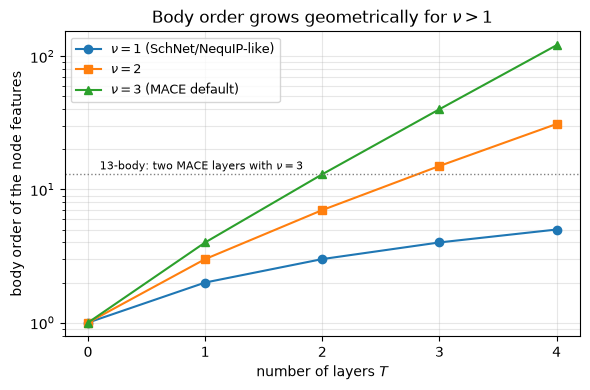

In [2]:
def body_order(nu, T):
    """Body order of the node features after T layers:
    b_t = nu * b_(t-1) + 1, b_0 = 1."""
    
    # Set the initial body order to 1 (the chemical element)
    b = 1    
    
    # Iteratively compute the body order for T layers
    for _ in range(T):
        b = nu * b + 1

    return b

print(f"two MACE layers with nu = 3: {body_order(3, 2)}-body features")

# Body order against the number of layers for nu = 1, 2, 3
layers = list(range(5))
fig, ax = plt.subplots(figsize=(6, 4))
for nu, marker, note in [(1, "o", " (SchNet/NequIP-like)"), (2, "s", ""), (3, "^", " (MACE default)")]:
    ax.semilogy(layers, [body_order(nu, T) for T in layers], marker + "-", label=rf"$\nu = {nu}${note}")
ax.axhline(13, color="gray", ls=":", lw=1)
ax.text(0.1, 14, r"13-body: two MACE layers with $\nu = 3$", fontsize=8, color="black")
ax.set_xlabel("number of layers $T$")
ax.set_ylabel("body order of the node features")
ax.set_xticks(layers)
ax.set_title(r"Body order grows geometrically for $\nu > 1$")
ax.legend(fontsize=9)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()

In message passing models such as MACE, information travels as one cutoff $r_c$ per
layer. As such, a message passing neural networks with $T$ layers can capture the
atomic interactions up to $T r_c$ away from the central atom. 

Let's compare the receptive fields of a NequIP-like model ($T = 5$, $r_c = 4$ Å)
and MACE ($T = 2$, $r_c = 5$ Å).

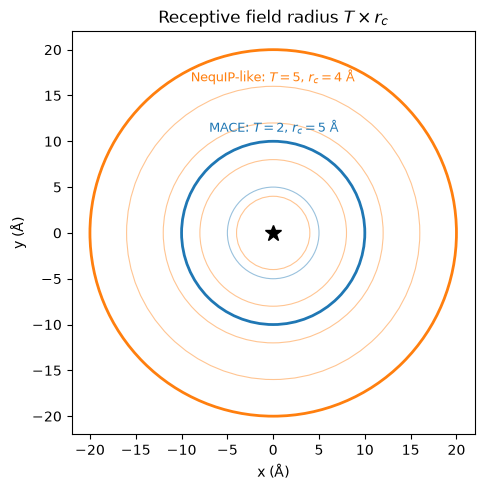

In [3]:
fig, ax = plt.subplots(figsize=(5, 5))
for T, r_c, color, name, position in [(5, 4.0, "C1", r"NequIP-like: $T = 5$, $r_c = 4$ Å", (-9., 16.5)),
                            (2, 5.0, "C0", r"MACE: $T = 2$, $r_c = 5$ Å", (-7., 11.))]:
    # One circle per layer; The outermost layer (t = T) bounds the receptive field
    for t in range(1, T + 1):
        ax.add_patch(plt.Circle((0, 0), t * r_c, fill=False, color=color,
                                lw=2 if t == T else 0.8, alpha=1.0 if t == T else 0.45))
    ax.text(0.4, T * r_c - 1.9, name, color=color, fontsize=9, position=position)

# The central atom
ax.plot(0, 0, "k*", markersize=12)
ax.set_xlim(-22, 22)
ax.set_ylim(-22, 22)
ax.set_aspect("equal")
ax.set_xlabel("x (Å)")
ax.set_ylabel("y (Å)")
ax.set_title(r"Receptive field radius $T \times r_c$")
fig.tight_layout()

This plot demonstrates why MACE parallelizes well. With $T = 2$, the receptive
field of MACE has a radius of $2 \times 5 = 10$ Å vs. $5 \times 4 = 20$ Å in
NequIP. When a large system is split into separate domains on multiple GPUs, far
less halo data must be exchanged at every molecular dynamics step which is
extremely important for scaling machine learning interatomic potentials to large
systems.

## The design-space view

[Batatia et al.](https://doi.org/10.1038/s42256-024-00956-x) provide a framework
for models such as Multi-ACE (MACE), NequIP, BOTNet, linear ACE, SchNet, DimeNet
to become special cases of a unified architecture design space. The construction
extends the one-particle basis of equivariant ACE to depend on the features of
the previous layers:

$$\phi^{(t)}_{kvL}\big(\sigma_i^{(t)}, \sigma_j^{(t)}\big) = R^{(t)}_{kcl_1L}(r_{ji})\, Y^{(l_1)}_{m_1}(\hat r_{ji})\, T^{(t)}_{kcL}\big(h_j^{(t)}, \theta_i, \theta_j\big),$$

where $R$'s are radial functions, $Y$'s are spherical harmonics, $T$'s are
generic node embedding functions, $v \equiv (l_1 m_1 c)$ is a multi-index
symbol, and $\theta$'s denote fixed node attributes such as the chemical element
types. Pooling and symmetrizing operations are exactly the same as those adopted
in ACE, which are also adopted in MACE's central equation for creating the
messages:

$$m^{(t)}_{i,kLM} = \sum_{\eta} w^{(t)}_{i,k\eta L} \sum_{\boldsymbol v} \mathcal C^{LM}_{\eta,\boldsymbol v} \prod_{\xi=1}^{\nu} \sum_{j \in \mathcal N(i)} \phi^{(t)}_{kv_\xi L}\big(\sigma_i^{(t)}, \sigma_j^{(t)}\big),$$

which is followed by a linear update to map them to the site energies. In this
design space, selecting each architecture amounts to setting a small group of
hyperparameters and implementation choices: the number of layers $T$, the
correlation order $\nu$, the largest message symmetry $L_{\max}$ (invariant or
equivariant messages), the internal $l_{\max}$, how channels and elements are
coupled, and where the nonlinearities are placed. Table 1 in [Batatia et
al.](https://doi.org/10.1038/s42256-024-00956-x) summarizes the design space of
several models based on these hyperparameters:

| Model | internal $l_{\max}$ | update $L_{\max}$ | $\nu$ | $T$ | total correlation order | coupling |
|---|---|---|---|---|---|---|
| SOAP        | $\ge 3$ | $0$      | $2$      | $1$      | $\ge 3$        | $nlm$ |
| Linear ACE  | $\ge 1$ | $0$      | $\ge 2$  | $1$      | $\ge 3$        | $nlm$ |
| SchNet      | $0$     | $0$      | $1$      | $\ge 2$  | $T$            | $\emptyset$ |
| DimeNet     | $0$     | $0$      | $2$      | $\ge 2$  | $2T$           | $\emptyset$ |
| Cormorant   | $\ge 1$ | $\ge 1$  | $1$      | $\ge 2$  | $T$            | $lm$ |
| NequIP      | $\ge 1$ | $\ge 1$  | $1$      | $\ge 2$  | $T$            | $l_1 m_1 l_2 m_2$ |
| **MACE**    | $\ge 1$ | $\ge 0$  | $\ge 1$  | $\ge 1$  | $\sim \nu T + T$ | $l_1 m_1 l_2 m_2$ |

The "coupling" column lists the indices of the one-particle basis that are
coupled when the product basis is created. Models can be read as:

- **SchNet** is the corner point of this design space with $l_{\max} = 0$, and
  $\nu = 1$ which gives a model with invariant 2-body messages.
- **DimeNet** adds directional information into the features. That is, with $\nu
  = 2$, the model uses invariant 3-body messages.
- **NequIP** is an equivariant model that keeps $\nu = 1$ but increases the body
  order through the architectural depth and by adding nonlinearities.
- **Linear ACE** uses a large value of $\nu$ in a single layer within a fixed
  basis.
- **MACE** is the general point in the design space with both $\nu > 1$ and $T >
  1$. It can reach a high body order with a small number of layers, while
  keeping the messages equivariant and the features learnable.
- **BOTNet** keeps NequIP's equivariant 2-body messages ($\nu = 1$) but makes
  the updates linear, so its body order grows by exactly one per layer (next
  section).

## From NequIP to BOTNet

NequIP is accurate, but its architecture mixes several ingredients: equivariant
tensor products, nonlinear gated updates, residual connections and a learnable
radial basis. [Batatia et al.](https://doi.org/10.1038/s42256-024-00956-x)
conducted an ablation study of NequIP to find out which ingredients are more
important for performance. From the results of this study, they built a
simplified model called Body-Ordered Tensor Network (BOTNet).

### The architecture of BOTNet

BOTNet keeps NequIP's equivariant tensor-product convolution, with 2-body
messages ($\nu = 1$), and its learnable radial basis. It removes all pointwise
nonlinearities from the updates, except in the last layer. Without them, a layer
only couples each neighbor's features with one more bond vector. Thus, the node
features after layer $t$ are exactly $(t + 1)$-body functions. This is the $\nu
= 1$ case of the recursion $b_t = \nu\, b_{t-1} + 1$ from the body-order
accounting section of this lesson.

### BOTNet's body-ordered energy

Like MACE, BOTNet adds a site energy term from the invariant features of every
layer. All readouts in BOTNet are linear except the last one, which is a
nonlinear function, $F$. Denoting the vector of invariant ($L = 0$) channels of
atom $i$ after layer $t$ by $h^{(t)}_{i,00}$, the site energy can be written as

$$E_i = E_i^{(0)} + \sum_{t=1}^{T-1} W^{(t)} h^{(t)}_{i,00} + F\big(W^{(T)} h^{(T)}_{i,00}\big).$$

Here, each linear term holds the contribution of one body order, and $F$
collects the residual higher-order contributions that the truncated expansion
misses. The energy can therefore be split into 1-body, 2-body, 3-body, ...
contributions, which makes the model interpretable. For instance, in a
hydrogen-transfer reaction in acetylacetone, [Batatia et
al.](https://doi.org/10.48550/arXiv.2205.06643) show that these contributions
shrink as the body order grows.

The BOTNet experiments, conducted by [Batatia et
al.](https://doi.org/10.48550/arXiv.2205.06643), highlight several important
points:

1. **Linear updates are enough for many practical applications:** As BOTNet can
   match NequIP's accuracy on several benchmark datasets, the equivariant tensor
   products should be prioritized over nonlinear updates.
2. **If nonlinearities are used, they must be chosen with care:** In NequIP,
   replacing SiLU with $\tanh$ makes the model performance significantly worse,
   even worse than using no nonlinearity. A likely reason is that $\tanh$
   suffers from vanishing gradients for large inputs which slows down the
   learning during training. By contrast, a single nonlinear readout in the last
   layer of BOTNet improves the model performance, significantly.
3. **The learned element embeddings make the model size independent of the
   number of elements:** Linear ACE gives every combination of $\nu$ elements
   its own basis functions. As such, the number of basis functions grow as
   $S^\nu$ for $S$ elements. In comparison, NequIP, BOTNet and MACE map each
   chemical element to a learned vector of $k$ channels. The channels are not
   coupled during the construction of the product basis. Therefore, the number
   of features stays the same for any number of elements, $S$. Exercise 3
   focuses on this aspect.

The aforementioned conclusions from BOTNet experiments demonstrate that a
linear, body-ordered model can be as accurate as NequIP. However, each layer in
BOTNet can raise the body order only by one. On the other hand, while MACE keeps
the linear and body-ordered structure of BOTNet, it can raise the correlation
order $\nu$ inside each layer as well. The learning curves of the [MACE
paper](https://proceedings.neurips.cc/paper_files/paper/2022/file/4a36c3c51af11ed9f34615b81edb5bbc-Paper-Conference.pdf)
(force errors against training-set size for aspirin) show that there are two
independent routes available to MACE for improving an invariant 2-body model:

- **A higher correlation order, which makes the learning curves steeper:** With
  invariant messages ($L = 0$), the slope of the log-log curve goes from $-0.33$
  for $\nu = 1$ to $-0.51$ for $\nu = 2$ and $-0.64$ for $\nu = 3$. Thus, the
  training (force) error falls faster as more data are provided to the model
  during the training.
- **Equivariant messages can shift the learning curves:** At $\nu = 3$, adding
  $L = 1$ or $L = 2$ messages can lower the error at each training-set size, while
  the slope stays almost the same.

## Why MACE is data-efficient?

The data efficiency of MACE results from the following design choices:

1. **No sums over groups of neighbors:** A model with $N_c$ neighbors per atom,
   that builds $(\nu + 1)$-body terms explicitly, must loop over all atomic
   pairs, triplets, ... of neighbors, at a cost that grows as $N_c^\nu$. MACE
   sums over the neighbors only once in order to build the $A$-basis (a cost
   proportional to $N_c$). It then multiplies $\nu$ copies of the $A$-basis on
   each atom to form the $B$-basis. This is the density trick, introduced in
   Lesson 10a. The generalized Clebsch-Gordan coefficients that couple the basis
   functions are sparse and often pre-computed. Therefore, constructing the
   $B$-basis costs a few small contractions per atom. Exercise 2 shows that the
   angular information is still preserved in the $B$-basis.
2. **MACE adopts two message-passing layers:** With two layers and $\nu = 3$,
   MACE achieves up to 13-body features. Since every layer gathers features from
   all neighbors, fewer layers are required to achieve high body orders with
   less work. The smaller receptive fields (e.g., $2 r_c$) make it easier to
   split a large system over several GPUs, compared to models with larger
   numbers of layers and receptive fields.
3. **Expensive work on the atoms, not on the edges:** An edge connects a pair of
   neighboring atoms $(i, j)$. A system of $N$ atoms with $N_c$ neighbors per
   atom, has $N N_c$ edges, typically tens of times more than the number of
   atoms. Work done once per edge and, therefore, costs far more than work done
   once per atom. Meanwhile, MACE keeps the per-edge work small:
   - The most expensive per-edge operation of an equivariant message-passing
     network is the tensor product of the edge spherical harmonics,
     $Y^{(l_1)}(\hat r_{ji})$, with the neighboring features, $h_j^{(t)}$. In
     the first MACE layer, $h_j^{(1)}$ is an invariant element embedding ($l_2 =
     0$). Thus, the tensor product reduces to multiplying $Y^{(l_1)}(\hat
     r_{ji})$ by a scalar weight $W_{kz_j}$. The full edge tensor product is
     needed only from the second layer on, which runs only once in the default
     two-layer MACE model.
   - The higher-order products that form the $B$-basis come after the sum over
     neighbors. They act on the pooled $A$-basis on each atom and run $N$ times
     instead of $N N_c$ times.
4. **A cost independent of the number of elements:** Learning the element
   embeddings in MACE replaces the $S^\nu$ element combinations of linear ACE.
      Only the embedding matrix $W_{kz}$ of the first layer grows linearly with
      $S$.
5. **Most operations involve simple linear algebra:** The message, the update
   and all readouts except the last one are linear mapping operations, which can
   be represented as fast matrix multiplications on GPUs. The only nonlinear
   functions are the radial MLP, the readout MLP of the last layer and the
   polynomial products of the $B$-basis.

The [MACE
paper](https://proceedings.neurips.cc/paper_files/paper/2022/file/4a36c3c51af11ed9f34615b81edb5bbc-Paper-Conference.pdf)
measures these gains on the 3BPA benchmark, with all models implemented in the
same code and run on NVIDIA A100 GPUs. Invariant MACE ($L = 0$) evaluates about
10 times faster than BOTNet and NequIP at similar accuracy. MACE with $L = 1$
and $L = 2$ is about 5 and 4 times faster, respectively, while being more
accurate. Training is faster as well: MACE reaches the accuracy of a converged
BOTNet model in about 30 minutes, whereas BOTNet needs more than a day. Fast
training matters in practice, because training sets for materials are often
built by active learning, which requires frequent retraining of the model or a
committee of models.

## Summary

In this lesson, we have learned:

- **MACE is ACE inside message passing:** Each layer builds an atomic basis
  $A^{(t)}$ from radial functions, spherical harmonics and learned neighbor
  embeddings. Tensor products with generalized Clebsch-Gordan coefficients turn
  the $A$-basis into higher-order equivariant $B$-features without any sum over
  neighboring tuples.
- **Linear message, update and readout:** MACE's fundamental equations are
  linear, except for the radial MLP and the readout MLP of the last layer. Each
  layer adds a site energy computed from its invariant features.
- **Body order:** The correlation order, $\nu$, sets the body order of one layer
  ($\nu + 1$ with respect to the node states). Layers compound the body order as
  $b_t = \nu\, b_{t-1} + 1$. Therefore, two layers with $\nu = 3$ give 13-body
  features while the receptive field stays at $2 r_c$.
- **Design space:** The choices of $\nu$, $T$, $L_{\max}$, $l_{\max}$ and the
  coupling of channels unify the architectural design of SchNet, DimeNet,
  NequIP, BOTNet, linear ACE and MACE within one framework. A higher $\nu$ makes
  the learning curves steeper, while equivariance can only shift them.
- **Speed:** Two layers, precomputed sparse contractions on the nodes, an
  inexpensive first layer and a cost that does not grow with the number of
  elements make the MACE architecture fast and data-efficient.

**Next:** In [Lesson 10c](10c_mace_implementation.ipynb), we build a simplified
version of MACE in e3nn, verify its equivariance and train it on a benchmark
dataset.

## Exercises

**1. Body order against depth (Difficulty: 🌶️):** The body order of the node
features after $T$ layers follows the recursion $b_t = \nu\, b_{t-1} + 1$ with
$b_0 = 1$. Consider a message-passing model with 2-body messages and $\nu = 1$:

- How many layers does a $\nu = 1$ message-passing model need to reach the
  13-body features of two MACE layers with $\nu = 3$?
- With a cutoff radius of $r_c = 5$ Å per layer, the receptive field is $T r_c$.
  Compare the receptive fields of the two message-passing and MACE models
  (assume the default settings with $T = 2$ and $\nu = 3$).
- Liquid water contains about 0.1 atoms per Å$^3$. How many atoms lie inside one
  receptive field of each model? What does the difference mean for running
  molecular dynamics (MD) of a large system decomposed over several GPUs?

<details><summary>Solution</summary>

For $\nu = 1$ the recursion gives $b_T = T + 1$. So, $T = 12$ layers are needed
to achieve 13-body features.

```python
import math

# MACE: nu = 3 and two layers, with a cutoff of 5 Å per layer
r_c = 5.0

# Defined in the Body-order accounting section of this lesson
b_mace = body_order(3, 2)

# Smallest number of layers for which a nu = 1 model reaches the same body order
T_nu1 = next(T for T in range(1, 100) if body_order(1, T) >= b_mace)

# Atoms inside one receptive field (a sphere of radius T * r_c) of liquid water
n_water = 0.1  # atoms per Å^3

# Compare the receptive fields of the two models
for name, nu, T in [("MACE,  nu = 3", 3, 2), ("MPNN,  nu = 1", 1, T_nu1)]:
  # Receptive field radius and number of atoms in it
  R = T * r_c
  n_atoms = 4 / 3 * math.pi * R**3 * n_water

  # Print the comparison
  print(f"{name}: T = {T:2d} -> {body_order(nu, T)}-body, receptive field {R:.0f} Å, "
        f"~{n_atoms:,.0f} atoms in it")
```

Output:

```text
MACE,  nu = 3: T =  2 -> 13-body, receptive field 10 Å, ~419 atoms in it
MPNN,  nu = 1: T = 12 -> 13-body, receptive field 60 Å, ~90,478 atoms in it
```

The receptive field is $12 \times 5 = 60$ Å for the $\nu = 1$ message-passing
model against $2 \times 5 = 10$ Å for MACE, and it holds about 200 times more
atoms. In spatial domain decomposition, when a large system is split over
multiple GPUs, each GPU must also hold a copy of every atom within one receptive
field of its own domain (the halo) and exchange the contributions from these
atoms with its neighbors at every MD step. A 60 Å halo holds far more atoms than
a typical domain. So, the communication, especially between atoms in different
domain segments (between GPUs), dominates the run time.

Note that equal body order between models (e.g., comparing MACE with a $\nu = 1$
message-passing model above) does not mean equal expressiveness: compared with
MACE, the 2-body message-passing models, which raise the body order by stacking
layers or through nonlinearities, can only generate a subset of all possible
higher-order features.

</details>

**2. Angles without triplets (Difficulty: 🌶️🌶️):** DimeNet builds bond angles
explicitly by looping over triplets of atoms $(j_1, i, j_2)$. This exercise
shows that MACE can capture the same angular information without looping over
atomic triplets.

Take the first MACE layer and one channel $k$. Write the $A$-basis of atom $i$
as

$$A_{lm} = \sum_j \rho_j\, Y^{(l)}_m(\hat r_{ij}),$$

where $\rho_j$, defined as

$$\rho_j = R_{kl}(r_{ij})\, W_{kz_j},$$

collects the radial function and the element weight. The unit vector, $\hat
r_{ij}$, goes from atom $i$ to its neighbor $j$. A $\nu = 2$, $L = 0$ feature is
the dot product of two copies of $A$,

$$B_l = \sum_m A_{lm}\, A_{lm}.$$

Note that in e3nn's real basis, this dot product equals the Clebsch-Gordan
coupling $l \otimes l \to 0$ up to a constant factor.

- Show that $B_l$ depends on the bond angles $\theta_{j_1 i j_2}$, although no
  angle is ever computed.
- Verify your result numerically for $l = 0, \dots, 3$.

*Hint:* Use the addition theorem of the spherical harmonics. For e3nn's real
harmonics with `normalization="component"`, we can write

$$\sum_m Y^{(l)}_m(\hat a)\, Y^{(l)}_m(\hat b) = (2l + 1)\, P_l(\hat a \cdot \hat b),$$

where $P_l$ is the Legendre polynomial of degree $l$ and $\hat a \cdot \hat b$
is the cosine of the angle between the two unit vectors.

<details><summary>Solution</summary>

Insert the neighbor sums of the two $A$'s, swap the order of the sums and
apply the addition theorem:

$$B_l = \sum_{j_1, j_2} \rho_{j_1} \rho_{j_2} \sum_m Y^{(l)}_m(\hat r_{ij_1})\, Y^{(l)}_m(\hat r_{ij_2}) = (2l + 1) \sum_{j_1, j_2} \rho_{j_1} \rho_{j_2}\, P_l(\cos\theta_{j_1 i j_2}).$$

The right-hand side is a sum over all pairs of neighbors:

- The terms with $j_1 = j_2$ have $\cos\theta = 1$ and $P_l(1) = 1$. They are
  the 2-body self-interaction terms, mentioned in Lesson 10a.
- Every other term is a 3-body function of the two bond lengths (through
  $\rho_{j_1}$ and $\rho_{j_2}$) and of the bond angle $\theta_{j_1 i j_2}$.
  This is the angular information that DimeNet builds by looping over
  triplets.

MACE computes the left-hand side, which needs one sum over the $N_c$ neighbors
and $2l + 1$ products. The right-hand side, which DimeNet-like models compute,
needs a sum over $N_c^2$ pairs.

Let's verify this numerically:

```python
# A random atomic environment: 8 neighbors of atom i at distances between 1 and 4 Å
vecs = torch.randn(8, 3)

# Scale the random directions to distances between 1 and 4 Å
vecs = vecs / vecs.norm(dim=-1, keepdim=True) * (1.0 + 3.0 * torch.rand(8, 1))
r = vecs.norm(dim=-1)

# A stand-in for the learned radial weights R_kl(r_ij) W_kz_j of one channel k
rho = torch.exp(-r)

# Cosines of all bond angles theta_(j1 i j2), including j1 = j2
unit = vecs / r[:, None]
cos = unit @ unit.T

# Compare the two expressions for each angular momentum l = 0, 1, 2, 3
for l in range(4):

    # First-layer A-basis of channel k (real spherical harmonics, component normalization)
    Y = o3.spherical_harmonics(l, vecs, normalize=True, normalization="component")
    A = (rho[:, None] * Y).sum(dim=0)

    # nu = 2, L = 0 feature: the dot product of two copies of A
    B2 = (A * A).sum()

    # Explicit sum over neighbor pairs of Legendre polynomials of the bond angle
    P_l = torch.special.legendre_polynomial_p(cos, l)
    pairs = (2 * l + 1) * (rho[:, None] * rho[None, :] * P_l).sum()

    # Print the two expressions and verify that they are numerically close
    print(f"l = {l}:  sum_m A_lm A_lm = {B2:.12f}   (2l+1) sum_j1j2 rho rho P_l = {pairs:.12f}")
    assert torch.isclose(B2, pairs)
```

Output:

```text
l = 0:  sum_m A_lm A_lm = 1.381016622398   (2l+1) sum_j1j2 rho rho P_l = 1.381016622398
l = 1:  sum_m A_lm A_lm = 1.042940782722   (2l+1) sum_j1j2 rho rho P_l = 1.042940782722
l = 2:  sum_m A_lm A_lm = 0.318847960114   (2l+1) sum_j1j2 rho rho P_l = 0.318847960114
l = 3:  sum_m A_lm A_lm = 1.820172571836   (2l+1) sum_j1j2 rho rho P_l = 1.820172571836
```

</details>

**3. Element channels (Difficulty: 🌶️):** A basis that couples the chemical
elements, such as linear ACE, needs one set of features for every combination of
$\nu$ elements, that is, $S^\nu$ combinations for $S$ elements, for every radial
and angular coupling. However, MACE embeds each element into $k$ learned
channels and does not couple the elements in the $B$-basis products. Therefore,
the number of features in MACE stays at $k$ for any $S$. 

Let $\nu = 3$ and the $k = 256$ channels, used in the experiments of the MACE
paper. Then answer the following questions:

- How many element combinations does a coupled basis need for 5 elements?
- From which $S$ on does $S^3$ exceed $k = 256$?
- How many combinations would the 89 elements of the Materials Project data
  require? (The MACE-MP-0 foundation model was trained on this data corpus.)

<details><summary>Solution</summary>

For 5 elements, a coupled basis needs $5^3 = 125$ element combinations, already
half of MACE's 256 channels.

```python
# Fixed parameters
nu, k = 3, 256

# Element combinations per (radial and angular) coupling of a coupled basis 
for S in (1, 2, 5, 7, 89):
    print(f"S = {S:2d} elements: S^nu = {S ** nu:7,d} combinations   (MACE: k = {k} channels)")

# Smallest number of elements for which S^nu exceeds k
S_cross = next(S for S in range(1, 100) if S ** nu > k)
print(f"S^{nu} exceeds k = {k} from S = {S_cross} on")
```

Output:

```text
S =  1 elements: S^nu =       1 combinations   (MACE: k = 256 channels)
S =  2 elements: S^nu =       8 combinations   (MACE: k = 256 channels)
S =  5 elements: S^nu =     125 combinations   (MACE: k = 256 channels)
S =  7 elements: S^nu =     343 combinations   (MACE: k = 256 channels)
S = 89 elements: S^nu = 704,969 combinations   (MACE: k = 256 channels)
S^3 exceeds k = 256 from S = 7 on
```

- $S^3$ exceeds 256 from $S = 7$ on ($6^3 = 216$, $7^3 = 343$).
- For the 89 elements of the Materials Project data, a coupled basis would
  need $89^3 = 704{,}969$ combinations for every coupling, which is far too
  many!

In MACE, only the element embedding $W_{kz}$ of the first-layer $A$-basis
grows with $S$, and it grows linearly ($k \times S$ weights), while the number
of features stays at $k$. This is why learned element embeddings are essential
for universal potentials that cover most of the periodic table.

</details>

## References

- [Batatia et al., *Adv. Neural Inf. Process. Syst.* **35**, 11423 (2022)](https://proceedings.neurips.cc/paper_files/paper/2022/file/4a36c3c51af11ed9f34615b81edb5bbc-Paper-Conference.pdf)
- [Batatia et al., *Nat. Mach. Intell.* **7**, 56 (2025)](https://doi.org/10.1038/s42256-024-00956-x) ([arXiv:2205.06643](https://arxiv.org/abs/2205.06643))
- [Kovács et al., *J. Chem. Phys.* **159**, 044118 (2023)](https://doi.org/10.1063/5.0155322)
- [Drautz, *Phys. Rev. B* **99**, 014104 (2019)](https://doi.org/10.1103/PhysRevB.99.014104)
- [Dusson et al., *J. Comput. Phys.* **454**, 110946 (2022)](https://doi.org/10.1016/j.jcp.2022.110946)
- [Kovács et al., *J. Am. Chem. Soc.* **147**, 17598 (2025)](https://doi.org/10.1021/jacs.4c07099)
- [Batatia et al., arXiv:2401.00096 (2024)](https://arxiv.org/abs/2401.00096)
- [Chong et al., *J. Chem. Phys.* **164**, 064121 (2026)](https://doi.org/10.1063/5.0303302)